In [1]:
import glob
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

files = glob.glob('/kaggle/input/**/*.xlsx', recursive=True)
assert len(files) > 0, "Excel file not found! Upload it via '+ Add Input' first."

DATA_PATH = files[0]
print("Loaded file:", DATA_PATH)

df = pd.read_excel(DATA_PATH, sheet_name='Form responses 1')
print("Dataset shape:", df.shape)
df.head(3)

Loaded file: /kaggle/input/datasets/asifalidewan/student-spending-survey/Student_Spending_Survey_200_Responses.xlsx
Dataset shape: (200, 24)


,Timestamp,Gender,Age (Years),Year of study,University type,Where you live,Total monthly money available (Tk),Main source of money,Do you earn your own income?,Monthly rent/accommodation (Tk),...,Money saved per month (Tk),Mobile banking use (bKash/Nagad/Rocket),Borrowed money from friends in last 3 months,Awareness of own spending (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I always know roughly how much money I have left.],Awareness of own spending (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I keep track of where most of my money goes each week.],Awareness of own spending (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I check my balance/expenses before making non-essential purchases.],Impulse buying (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I often buy things on the spur of the moment without planning.],"Impulse buying (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I find it hard to resist discounts, flash sales, or cravings.]",Impulse buying (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I frequently regret unplanned purchases shortly after buying them.],Do you often run out of money before the end of the month?
0,2026-11-15 00:14:28.756,Male,24,4th year,Private,With family,<5k,Family,No,6–9k,...,0,Weekly,3+,5,4,1,5,4,1,Yes
1,2026-11-20 20:46:49.990,Male,23,4th year,Private,Rented flat,5–10k,Family,No,3–6k,...,0,Daily,Never,4,4,5,4,4,3,Yes
2,2026-11-20 20:53:33.623,Male,23,1st year,National University college,Hall,15–20k,Mixed,No,3–6k,...,<500,Rarely,3+,4,4,3,2,3,4,Yes


**Cell 2 — Clean Data & Engineer Behavioral Scores**

In [2]:
df = df.drop(columns=['Timestamp'], errors='ignore')

TARGET_COL = 'Do you often run out of money before the end of the month?'
y = (df[TARGET_COL].astype(str).str.strip() == 'Yes').astype(int)
X = df.drop(columns=[TARGET_COL]).copy()

print("Class distribution (0 = Safe, 1 = At Risk):")
print(y.value_counts())

rename_map = {
    'Awareness of own spending (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I always know roughly how much money I have left.]': 'aware_balance',
    'Awareness of own spending (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I keep track of where most of my money goes each week.]': 'aware_weekly_track',
    'Awareness of own spending (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I check my balance/expenses before making non-essential purchases.]': 'aware_check_before_buy',
    'Impulse buying (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I often buy things on the spur of the moment without planning.]': 'impulse_spontaneous',
    'Impulse buying (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I find it hard to resist discounts, flash sales, or cravings.]': 'impulse_discounts',
    'Impulse buying (Rate each statement from 1 = Strongly Disagree to 5 = Strongly Agree) [I frequently regret unplanned purchases shortly after buying them.]': 'impulse_regret',
}
X = X.rename(columns=rename_map)

ordinal_maps = {
    'Year of study': ['1st year', '2nd year', '3rd year', '4th year', 'Masters'],
    'Total monthly money available (Tk)': ['<5k', '5–10k', '10–15k', '15–20k', '>20k'],
    'Monthly rent/accommodation (Tk)': ['0', '<3k', '3–6k', '6–9k', '>9k'],
    'Monthly food (Tk)': ['<3k', '3–5k', '5–7k', '>7k'],
    'Monthly transport (Tk)': ['<1k', '1–2k', '2–3k', '>3k'],
    'Monthly online shopping / eating-out / entertainment (Tk)': ['<1k', '1–2k', '>2k'],
    'Money saved per month (Tk)': ['0', '<500', '500–1k', '>1k'],
    'Mobile banking use (bKash/Nagad/Rocket)': ['Rarely', 'Weekly', 'Daily'],
    'Borrowed money from friends in last 3 months': ['Never', '1–2', '3+']
}

for col, order in ordinal_maps.items():
    mapping = {val: idx for idx, val in enumerate(order)}
    X[col] = X[col].astype(str).str.strip().map(mapping)

X['awareness_score'] = X[['aware_balance', 'aware_weekly_track', 'aware_check_before_buy']].mean(axis=1)
X['impulse_score'] = X[['impulse_spontaneous', 'impulse_discounts', 'impulse_regret']].mean(axis=1)

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

print("Any missing values?", X.isna().sum().sum())

Class distribution (0 = Safe, 1 = At Risk):
Do you often run out of money before the end of the month?
1    133
0     67
Name: count, dtype: int64
Any missing values? 0


**Cell 3 — Train & Compare 5 Models**

In [3]:
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols)
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42),
    'SVM (RBF)': SVC(probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc'}

results = []
for name, clf in models.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', clf)])
    cv_res = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    results.append({
        'Model': name,
        'Accuracy': round(cv_res['test_accuracy'].mean(), 4),
        'F1-Score': round(cv_res['test_f1'].mean(), 4),
        'ROC-AUC': round(cv_res['test_roc_auc'].mean(), 4)
    })

results_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]['Model']
print(f"\nBest model by ROC-AUC: {best_model_name}")

              Model  Accuracy  F1-Score  ROC-AUC
  Gradient Boosting     0.840    0.8787   0.9105
          SVM (RBF)     0.850    0.8870   0.9098
      Random Forest     0.835    0.8776   0.9033
Logistic Regression     0.855    0.8915   0.8982
      Decision Tree     0.800    0.8488   0.8169

Best model by ROC-AUC: Gradient Boosting


**Cell 4 — Confusion Matrix & Top Risk Drivers**

               precision    recall  f1-score   support

    Safe (No)       0.75      0.79      0.77        67
At Risk (Yes)       0.89      0.86      0.88       133

     accuracy                           0.84       200
    macro avg       0.82      0.83      0.82       200
 weighted avg       0.84      0.84      0.84       200



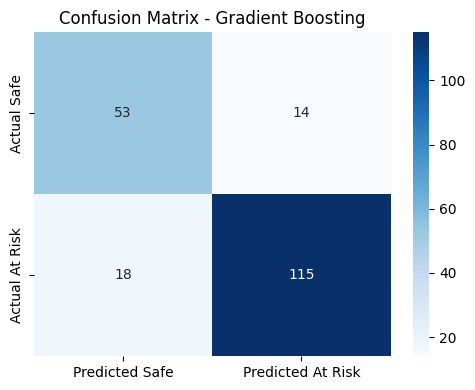

/tmp/ipykernel_16/3376746668.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')


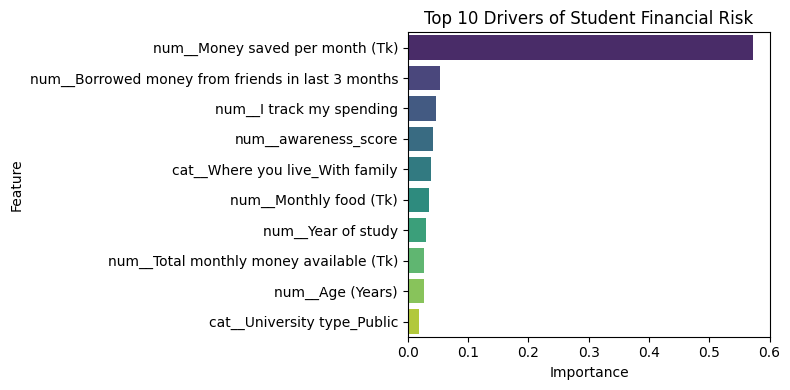

In [4]:
best_pipe = Pipeline([('pre', preprocessor), ('clf', models[best_model_name])])

y_pred_oof = cross_val_predict(best_pipe, X, y, cv=cv)
print(classification_report(y, y_pred_oof, target_names=['Safe (No)', 'At Risk (Yes)']))

cm = confusion_matrix(y, y_pred_oof)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Safe', 'Predicted At Risk'],
            yticklabels=['Actual Safe', 'Actual At Risk'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.show()

best_pipe.fit(X, y)

feature_names = best_pipe.named_steps['pre'].get_feature_names_out()
clf_step = best_pipe.named_steps['clf']
importances = getattr(clf_step, 'feature_importances_', None)
if importances is None and hasattr(clf_step, 'coef_'):
    importances = np.abs(clf_step.coef_[0])

if importances is not None:
    feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    feat_df = feat_df.sort_values('Importance', ascending=False).head(10)
    plt.figure(figsize=(8, 4))
    sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis')
    plt.title('Top 10 Drivers of Student Financial Risk')
    plt.tight_layout()
    plt.show()

**Cell 5 — Risk Score & Bilingual Warning System**

In [5]:
def predict_student_risk(student_row_df):
    prob = best_pipe.predict_proba(student_row_df)[0][1]
    risk_pct = round(prob * 100, 1)

    if risk_pct >= 70:
        tier = "HIGH RISK (উচ্চ ঝুঁকি)"
        warning = (
            "Warning: High likelihood of running out of money before month-end. "
            "Pause non-essential online shopping, set a weekly cash limit, and track every expense.\n"
            "সতর্কতা: মাস শেষ হওয়ার আগেই টাকা শেষ হয়ে যাওয়ার উচ্চ ঝুঁকি রয়েছে। অপ্রয়োজনীয় খরচ বন্ধ করুন এবং সাপ্তাহিক বাজেট ঠিক করুন।"
        )
    elif risk_pct >= 40:
        tier = "MODERATE RISK (মাঝারি ঝুঁকি)"
        warning = (
            "Caution: Moderate financial risk. Try to save at least 500–1,000 Tk/month "
            "and check your balance before impulse purchases.\n"
            "সতর্কতা: মাঝারি ঝুঁকি। প্রতি মাসে অন্তত ৫০০–১,০০০ টাকা সঞ্চয় করার চেষ্টা করুন।"
        )
    else:
        tier = "LOW RISK (কম ঝুঁকি)"
        warning = (
            "Good job! Your spending habits look stable. Keep tracking your expenses and saving consistently.\n"
            "অভিনন্দন! আপনার অর্থ ব্যবস্থাপনা ভালো অবস্থায় আছে। নিয়মিত হিসাব রাখা ও সঞ্চয় চালিয়ে যান।"
        )
    return {"risk_score_pct": risk_pct, "risk_tier": tier, "warning": warning}

for idx in [0, 4, 10]:
    res = predict_student_risk(X.iloc[[idx]])
    print(f"--- Student #{idx} (Actual: {'At Risk' if y.iloc[idx]==1 else 'Safe'}) ---")
    print(f"Risk Score: {res['risk_score_pct']}% | Tier: {res['risk_tier']}")
    print(res['warning'], "\n")

--- Student #0 (Actual: At Risk) ---
Risk Score: 98.3% | Tier: HIGH RISK (উচ্চ ঝুঁকি)
সতর্কতা: মাস শেষ হওয়ার আগেই টাকা শেষ হয়ে যাওয়ার উচ্চ ঝুঁকি রয়েছে। অপ্রয়োজনীয় খরচ বন্ধ করুন এবং সাপ্তাহিক বাজেট ঠিক করুন। 

--- Student #4 (Actual: Safe) ---
Risk Score: 2.7% | Tier: LOW RISK (কম ঝুঁকি)
Good job! Your spending habits look stable. Keep tracking your expenses and saving consistently.
অভিনন্দন! আপনার অর্থ ব্যবস্থাপনা ভালো অবস্থায় আছে। নিয়মিত হিসাব রাখা ও সঞ্চয় চালিয়ে যান। 

--- Student #10 (Actual: Safe) ---
Risk Score: 19.6% | Tier: LOW RISK (কম ঝুঁকি)
Good job! Your spending habits look stable. Keep tracking your expenses and saving consistently.
অভিনন্দন! আপনার অর্থ ব্যবস্থাপনা ভালো অবস্থায় আছে। নিয়মিত হিসাব রাখা ও সঞ্চয় চালিয়ে যান। 



**Cell 6 — Save Your Trained Model**

In [6]:
joblib.dump(best_pipe, 'financial_risk_model.pkl')
print("Saved trained model to financial_risk_model.pkl")

Saved trained model to financial_risk_model.pkl


**test new student**

In [7]:
new_student = pd.DataFrame([{
    'Gender': 'Male',
    'Age (Years)': 22,
    'Year of study': 2,            # 0=1st, 1=2nd, 2=3rd, 3=4th, 4=Masters
    'University type': 'Private',
    'Where you live': 'Mess-hostel',
    'Total monthly money available (Tk)': 1, # 0=<5k, 1=5-10k, 2=10-15k, 3=15-20k, 4=>20k
    'Main source of money': 'Family',
    'Do you earn your own income?': 'No',
    'Monthly rent/accommodation (Tk)': 2,    # 0=0, 1=<3k, 2=3-6k, 3=6-9k, 4=>9k
    'Monthly food (Tk)': 1,                  # 0=<3k, 1=3-5k, 2=5-7k, 3=>7k
    'Monthly transport (Tk)': 1,             # 0=<1k, 1=1-2k, 2=2-3k, 3=>3k
    'Monthly online shopping / eating-out / entertainment (Tk)': 1, # 0=<1k, 1=1-2k, 2=>2k
    'I track my spending': 2,                # 1 to 5
    'Money saved per month (Tk)': 0,         # 0=0, 1=<500, 2=500-1k, 3=>1k
    'Mobile banking use (bKash/Nagad/Rocket)': 2, # 0=Rarely, 1=Weekly, 2=Daily
    'Borrowed money from friends in last 3 months': 1, # 0=Never, 1=1-2, 2=3+
    'aware_balance': 2, 'aware_weekly_track': 2, 'aware_check_before_buy': 2,
    'impulse_spontaneous': 4, 'impulse_discounts': 4, 'impulse_regret': 3,
    'awareness_score': 2.0,
    'impulse_score': 3.67
}])

print(predict_student_risk(new_student))

{'risk_score_pct': np.float64(98.8), 'risk_tier': 'HIGH RISK (উচ্চ ঝুঁকি)', 'warning': 'Warning: High likelihood of running out of money before month-end. Pause non-essential online shopping, set a weekly cash limit, and track every expense.\nসতর্কতা: মাস শেষ হওয়ার আগেই টাকা শেষ হয়ে যাওয়ার উচ্চ ঝুঁকি রয়েছে। অপ্রয়োজনীয় খরচ বন্ধ করুন এবং সাপ্তাহিক বাজেট ঠিক করুন।'}
